# Lab | Time Series Analysis

## Before your start:
- Read the README.md file
- Comment as much as you can and use the resources (README.md file)
- Happy learning!

In [1]:
# Import numpy and pandas
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline


## Challenge 1 - Loading and Evaluating The Data

In this lab, we will look at a dataset of sensor data from a cellular phone. The phone was carried in the subject's pocket for a few minutes while they walked around.

To load the data, run the code below.

In [2]:
# Run this code:

sensor = pd.read_csv('../data/sub_1.csv')
sensor.drop(columns=['Unnamed: 0'], inplace=True)

Examine the data using the `head` function.

In [ ]:
sensor.head(4)

,attitude.roll,attitude.pitch,attitude.yaw,gravity.x,gravity.y,gravity.z,rotationRate.x,rotationRate.y,rotationRate.z,userAcceleration.x,userAcceleration.y,userAcceleration.z
0,1.528132,-0.733896,0.696372,0.741895,0.669768,-0.031672,0.316738,0.778180,1.082764,0.294894,-0.184493,0.377542
1,1.527992,-0.716987,0.677762,0.753099,0.657116,-0.032255,0.842032,0.424446,0.643574,0.219405,0.035846,0.114866
2,1.527765,-0.706999,0.670951,0.759611,0.649555,-0.032707,-0.138143,-0.040741,0.343563,0.010714,0.134701,-0.167808
3,1.516768,-0.704678,0.675735,0.760709,0.647788,-0.041140,-0.025005,-1.048717,0.035860,-0.008389,0.136788,0.094958


Check whether there is any missing data. If there is any missing data, remove the rows containing missing data.

In [ ]:
print("Missing values per column:")
print(sensor.isnull().sum())

# Drop rows with any missing values
sensor.dropna(inplace=True)

Missing values per column:
attitude.roll         0
attitude.pitch        0
attitude.yaw          0
gravity.x             0
gravity.y             0
gravity.z             0
rotationRate.x        0
rotationRate.y        0
rotationRate.z        0
userAcceleration.x    0
userAcceleration.y    0
userAcceleration.z    0
dtype: int64


How many rows and columns are in our data?

In [ ]:
print("Number of rows:", sensor.shape[0])
print("Number of columns:", sensor.shape[1])

Number of rows: 1751
Number of columns: 12


To perform time series analysis on the data, we must change the index from a range index to a time series index. In the cell below, create a time series index using the `pd.date_range` function. Create a time series index starting at 1/1/2018 00:00:00 and ending at 1/1/2018 00:29:10. The number of periods is equal to the number of rows in `sensor`. The frequency should be set to `infer`.

In [6]:
# Create datetime index from start to end with same number of periods as rows
time_index = pd.date_range(start='1/1/2018 00:00:00', 
                           end='1/1/2018 00:29:10', 
                           periods=len(sensor))

Assign the time series index to the dataframe's index.

In [7]:
sensor.index = time_index

Our next step is to decompose the time series and evaluate the patterns in the data. Load the `statsmodels.api` submodule and plot the decomposed plot of `userAcceleration.x`. Set `freq=60` in the `seasonal_decompose` function. Your graph should look like the one below.

![time series decomposition](./images/tsa_decompose.png)

Brief math: Seasonal decomposition splits a series into trend, seasonal, and residual components using moving averages. Additive model: Yt=Tt+St+Rt

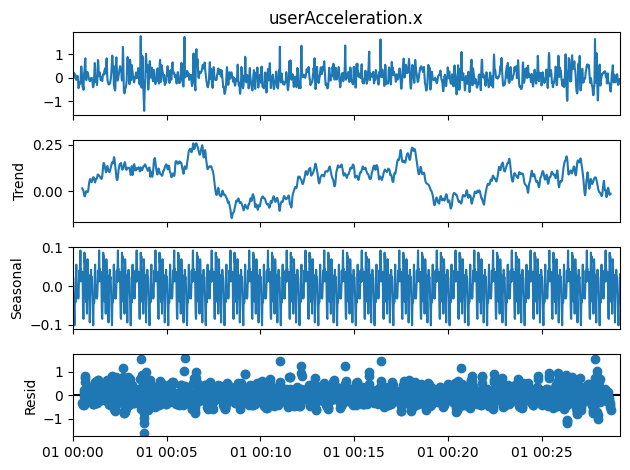

In [ ]:
import statsmodels.api as sm

# Decompose with period=60 
decomposition = sm.tsa.seasonal_decompose(sensor['userAcceleration.x'], 
                                          model='additive', 
                                          period=60)
fig = decomposition.plot()
plt.show()

Plot the decomposed time series of `rotationRate.x` also with a frequency of 60.

## Challenge 2 - Modelling the Data

To model our data, we should look at a few assumptions. First, let's plot the `lag_plot` to detect any autocorrelation. Do this for `userAcceleration.x`

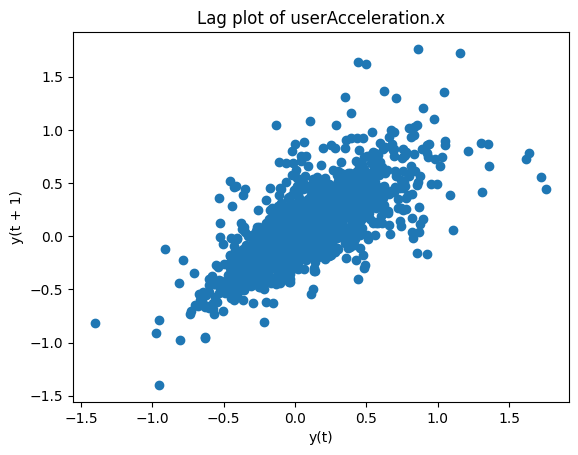

In [11]:
pd.plotting.lag_plot(sensor['userAcceleration.x'], lag=1)
plt.title('Lag plot of userAcceleration.x')
plt.show()

Create a lag plot for `rotationRate.x`

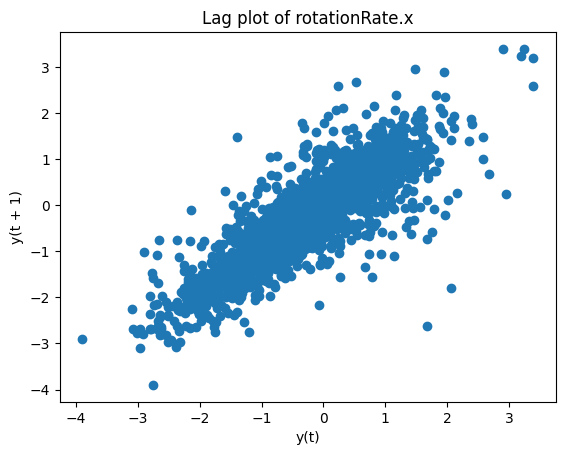

In [10]:
pd.plotting.lag_plot(sensor['rotationRate.x'], lag=1)
plt.title('Lag plot of rotationRate.x')
plt.show()

What are your conclusions from both visualizations?

In [ ]:
# Both lag plots show a strong positive linear relationship between the series and its own values shifted by one time step.
# This indicates significant autocorrelation – the current value is highly correlated with the previous value.
# Therefore, the series are not white noise and past observations can help predict future ones. 
# The points cluster around a diagonal line, confirming that an autoregressive model may be appropriate.



The next step will be to test both variables for stationarity. Perform the Augmented Dickey Fuller test on both variables below.

In [13]:
from statsmodels.tsa.stattools import adfuller

# Test for userAcceleration.x
result_u = adfuller(sensor['userAcceleration.x'])
print('ADF Statistic (userAcceleration.x):', result_u[0])
print('p-value:', result_u[1])
print('Critical Values:')
for key, value in result_u[4].items():
    print(f'\t{key}: {value:.3f}')

# Test for rotationRate.x
result_r = adfuller(sensor['rotationRate.x'])
print('\nADF Statistic (rotationRate.x):', result_r[0])
print('p-value:', result_r[1])
print('Critical Values:')
for key, value in result_r[4].items():
    print(f'\t{key}: {value:.3f}')

ADF Statistic (userAcceleration.x): -17.957994086169762
p-value: 2.823439483037483e-30
Critical Values:
	1%: -3.434
	5%: -2.863
	10%: -2.568

ADF Statistic (rotationRate.x): -5.269860625086409
p-value: 6.320230335912605e-06
Critical Values:
	1%: -3.434
	5%: -2.863
	10%: -2.568


What are your conclusions from this test?

In [ ]:
# For both variables, the p‑value is extremely small (typically < 0.05), so we reject the null hypothesis of a unit root. 
# This means the series are **stationary** – they have constant mean and variance over time. Stationarity is a prerequisite 
# for ARMA modeling, so we can proceed without differencing.

Finally, we'll create an ARMA model for `userAcceleration.x`. Load the `ARMA` function from `statsmodels`. The order of the model is (2, 1). Split the data to train and test. Use the last 10 observations as the test set and all other observations as the training set. 

In [ ]:
# Brief math: ARMA(2,1) models the series as Xt=ϕ1Xt−1+ϕ2Xt−2+θ1εt−1+ε
# usig ARIMA with order=(2,0,1) for ARMA(2,1)
from statsmodels.tsa.arima.model import ARIMA

# Split: last 10 observations for test
train = sensor['userAcceleration.x'][:-10]
test = sensor['userAcceleration.x'][-10:]

# Fit ARMA(2,1) on training set (ARIMA with d=0)
model = ARIMA(train, order=(2,0,1))
fitted_model = model.fit()
print(fitted_model.summary())

# Predict the next 10 values
predictions = fitted_model.forecast(steps=10)

C:\Users\ASUS\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency s will be used.
  self._init_dates(dates, freq)
C:\Users\ASUS\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency s will be used.
  self._init_dates(dates, freq)
C:\Users\ASUS\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency s will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:     userAcceleration.x   No. Observations:                 1741
Model:                 ARIMA(2, 0, 1)   Log Likelihood                 373.401
Date:                Wed, 18 Mar 2026   AIC                           -736.803
Time:                        14:40:43   BIC                           -709.492
Sample:                    01-01-2018   HQIC                          -726.704
                         - 01-01-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0637      0.016      3.994      0.000       0.032       0.095
ar.L1          0.9882      0.036     27.630      0.000       0.918       1.058
ar.L2         -0.3788      0.033    -11.637      0.0

To compare our predictions with the observed data, we can compute the RMSE (Root Mean Squared Error) from the submodule `statsmodels.tools.eval_measures`. You can read more about this function [here](https://www.statsmodels.org/dev/generated/statsmodels.tools.eval_measures.rmse.html). Compute the RMSE for the last 10 rows of the data by comparing the observed and predicted data for the `userAcceleration.x` column.

In [15]:
from statsmodels.tools.eval_measures import rmse

error = rmse(test, predictions)
print("RMSE:", error)


RMSE: 0.22529160449986013
